1. Desarrollar una función basada en ciclos que permita
aplicar un filtro ideal pasa bajos en 2D. Recibe como
entrada la imagen original y la frecuencia de corte.
Probar el algoritmo con las imágenes “rectOne.pgm”,
“nebulosaLira.pgm” y “gwen-pgm” con diversas
frecuencias de corte.

2. Desarrollar una función basada en ciclos que permita
aplicar un filtro Butterworth en 2D. Recibe como
entrada la imagen original, la frecuencia de corte y el
orden del filtro. Probar el algoritmo con las imágenes
“rectOne.pgm”, “nebulosaLira.pgm” y “gwen.pgm”
con diversas frecuencias de corte y diferente orden

3. Desarrollar una función basada en ciclos que permita
aplicar un filtro Gaussian en 2D. Recibe como
entrada la imagen original y la frecuencia de corte.
Probar el algoritmo con las imágenes “rectOne.pgm”,
“nebulosaLira.pgm” y “gwen-pgm” con diversas
frecuencias de corte.

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2

os.makedirs('results', exist_ok=True)

## Punto 1 
Desarrollar una función basada en ciclos que permita
aplicar un filtro ideal pasa bajos en 2D. Recibe como
entrada la imagen original y la frecuencia de corte.
Probar el algoritmo con las imágenes “rectOne.pgm”,
“nebulosaLira.pgm” y “gwen-pgm” con diversas
frecuencias de corte.

In [7]:
def filtro_ideal_paso_bajo(imagen, frecuencia_corte):
    if frecuencia_corte <= 0:
        raise ValueError("La frecuencia de corte debe ser mayor que cero.")

    # Obtener las dimensiones de la imagen
    filas, columnas = imagen.shape

    # Paso 1: Transformada de Fourier de la imagen
    transformada = np.fft.fft2(imagen)

    # Centrar las frecuencias
    transformada_centrada = np.fft.fftshift(transformada)

    # paso 2: Crear el filtro ideal de paso bajo, mascara ideal
    mascara = np.zeros((filas, columnas), dtype=np.float64)

    # Calcular el centro de la imagen
    centro_fila, centro_columna = filas // 2, columnas // 2

    for fila in range(filas):
        for columna in range(columnas):
            # Calcular la distancia desde el centro
            distancia = np.sqrt((fila - centro_fila) ** 2 + (columna - centro_columna) ** 2)
            if distancia <= frecuencia_corte:
                mascara[fila, columna] = 1
    # paso 3: Aplicar el filtro a la transformada centrada
    transformada_filtrada = transformada_centrada * mascara

    # paso 4: Transformada inversa de Fourier, regresar al dominio espacial
    transformada_inversa = np.fft.ifftshift(transformada_filtrada)

    imagen_filtrada = np.fft.ifft2(transformada_inversa)

    # paso 5: Tomar la parte real de la imagen filtrada
    imagen_filtrada_real = np.real(imagen_filtrada)

    return imagen_filtrada_real,mascara


In [8]:
# Cuadrado sintético de 256x256
cuadrado = np.zeros((256, 256), dtype=np.float64)
cuadrado[64:192, 64:192] = 255

# Fotografías en escala de grises
rostro = cv2.imread("images/rostro.png", cv2.IMREAD_GRAYSCALE)
paisaje = cv2.imread("images/paisaje.png", cv2.IMREAD_GRAYSCALE)

if rostro is None or paisaje is None:
    raise FileNotFoundError(
        "No se encontró alguna de las imágenes."
    )

imagenes = [cuadrado, rostro, paisaje]
titulos = ["Cuadrado", "Rostro", "Paisaje"]

for titulo, img in zip(titulos, imagenes):
    print(f"{titulo}: {img.shape}")

Cuadrado: (256, 256)
Rostro: (1200, 1200)
Paisaje: (533, 800)


In [ ]:
frecuencias = [20, 40, 80]

resultados = {}

for titulo, imagen_actual in zip(titulos, imagenes):

    resultados[titulo] = {}

    for corte in frecuencias:

        filtrada, mascara = filtro_ideal_paso_bajo(
            imagen_actual, corte
        )

        resultados[titulo][corte] = {
            "imagen": filtrada,
            "mascara": mascara
        }

    print(f"{titulo}: filtros aplicados correctamente")

Cuadrado: filtros aplicados correctamente
Rostro: filtros aplicados correctamente
Paisaje: filtros aplicados correctamente


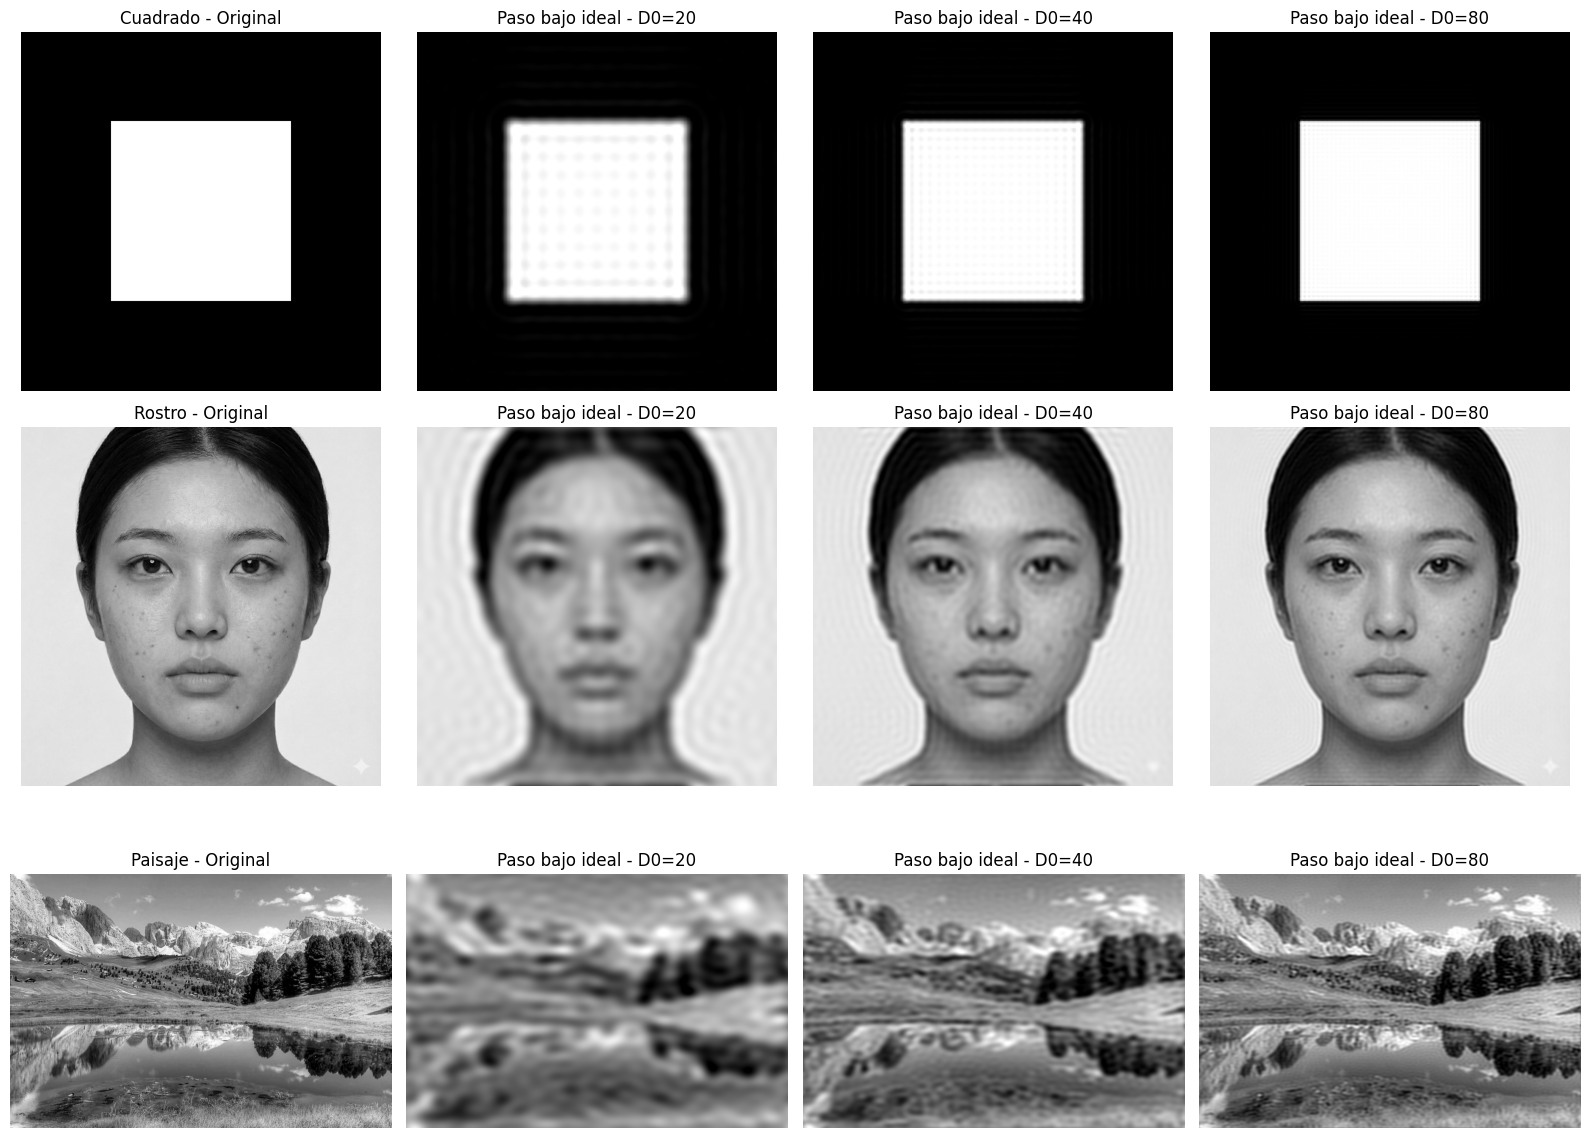

In [11]:
fig, axs = plt.subplots(3, 4, figsize=(16, 12))

for i, (titulo, imagen_actual) in enumerate(
    zip(titulos, imagenes)
):
    axs[i, 0].imshow(
        imagen_actual,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axs[i, 0].set_title(f"{titulo} - Original")
    axs[i, 0].axis("off")

    for j, corte in enumerate(frecuencias):

        imagen_filtrada = resultados[titulo][corte]["imagen"]

        axs[i, j + 1].imshow(
            imagen_filtrada,
            cmap="gray",
            vmin=0,
            vmax=255
        )

        axs[i, j + 1].set_title(f"Paso bajo ideal - D0={corte}")
        axs[i, j + 1].axis("off")

plt.tight_layout()
plt.savefig("results/filtro_ideal_paso_bajo.png")
plt.show()

### Análisis de resultados — Punto 1: Filtro ideal paso bajo

Se implementó un filtro ideal paso bajo en el dominio de la frecuencia mediante una función que recibe una imagen en escala de grises y una frecuencia de corte. La máscara del filtro se construyó utilizando ciclos anidados, calculando la distancia de cada posición respecto al centro del espectro.

El algoritmo se probó con tres imágenes: un cuadrado blanco sobre fondo negro, un rostro y un paisaje natural. Para cada imagen se utilizaron frecuencias de corte de 20, 40 y 80.

En la imagen del **cuadrado**, se observó que con una frecuencia de corte de 20 los bordes pierden definición y aparecen halos alrededor de la figura. Estos efectos disminuyen al aumentar la frecuencia de corte a 40 y 80, obteniendo bordes progresivamente más definidos.

En la imagen del **rostro**, el filtro con frecuencia de corte de 20 produce un suavizado considerable, reduciendo pequeñas variaciones de intensidad en la piel, pero también afectando la definición de los ojos, las cejas y el cabello. Al aumentar la frecuencia de corte, se recupera progresivamente la nitidez y se conservan más detalles. También se observan algunas bandas alrededor del contorno de la cabeza, relacionadas con el efecto de anillado del filtro ideal.

En el **paisaje**, el filtro con frecuencia de corte de 20 produce una pérdida notable de detalles en las montañas, los árboles y los reflejos del agua. Con una frecuencia de 40 se recuperan algunas texturas, mientras que con 80 la imagen conserva mayor definición y se aproxima más a la original.

Los resultados muestran que una frecuencia de corte menor produce un suavizado más intenso, debido a que se eliminan más componentes de alta frecuencia. Por el contrario, una frecuencia de corte mayor permite conservar más detalles.

También se evidenció el **efecto de anillado (*ringing*)**, especialmente en los bordes del cuadrado y alrededor del rostro. Este fenómeno aparece debido al corte abrupto de frecuencias que realiza el filtro ideal.

**En conclusión**, el filtro ideal paso bajo permite suavizar imágenes mediante la eliminación de frecuencias altas. Sin embargo, además de reducir detalles pequeños, puede generar oscilaciones alrededor de los bordes, por lo que sus resultados dependen de la frecuencia de corte y de las características de cada imagen.